In [15]:
import math as m
import scipy.stats as st
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import statsmodels.api as sm

from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

## Week 1

### Voorwaarden LSRM

0.7178106236775392


C:\Users\feeva\AppData\Local\Temp\ipykernel_26300\2988492775.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  r = data.corr().iloc[0][1]
C:\Users\feeva\AppData\Local\Temp\ipykernel_26300\2988492775.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  b_1 = r * data.std()[1] / data.std()[0]
C:\Users\feeva\AppData\Local\Temp\ipykernel_26300\2988492775.py:13: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x_bar = data.mean()[0]
C:\Us

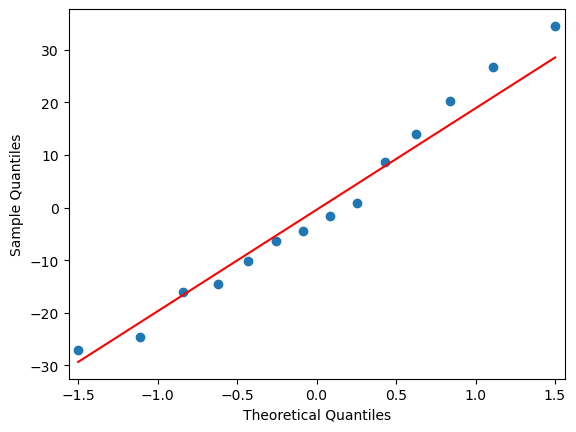

In [16]:
inputValues = {
    'age': [25, 25, 28, 32, 32, 32, 38, 42, 48, 51, 51, 58, 62, 65], 
    'cholesterol': [180, 195, 186, 180, 210, 197, 239, 183, 204, 221, 243, 208, 228, 269],
}
data = pd.DataFrame(inputValues)
#Sample randomnly distributed
r = data.corr().iloc[0][1]
n = len(data.index)
k = 1

b_1 = r * data.std()[1] / data.std()[0] 

x_bar = data.mean()[0]
y_bar = data.mean()[1]
b_0 = y_bar - b_1 * x_bar

#Residuals Normally distributed
model = ols('cholesterol ~ age', data = data).fit()
residuals = model.resid

sm.qqplot(residuals, line='q');
print(r)

## Week 5

### Correlation Matrix

In [17]:
inputvalues = {
    'age': [25,25,28,32,32,32,38,42,48,51,51,58,62,65],
    'fat': [19,28,19,16,24,20,31,20,26,24,32,21,21,30],
    'cholesterol': [180,195,186,180,210,197,239,183,204,221,243,208,228,269]
}
df = pd.DataFrame(inputvalues)
df.corr()

,age,fat,cholesterol
age,1.000000,0.324143,0.717811
fat,0.324143,1.000000,0.777837
cholesterol,0.717811,0.777837,1.000000


### Volledig tabel met veel waardes

In [18]:
#Kan ook handmatig mbv formules uit formuleblad

#met python:
x = df[['age', 'fat']]
y = df['cholesterol']

X = sm.add_constant(x)

model = sm.OLS(y,X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            cholesterol   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.820
Method:                 Least Squares   F-statistic:                     30.53
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           3.24e-05
Time:                        15:00:48   Log-Likelihood:                -52.270
No. Observations:                  14   AIC:                             110.5
Df Residuals:                      11   BIC:                             112.5
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         90.8415     15.989      5.682      0.0

c:\Users\feeva\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=14 observations were given.
  return hypotest_fun_in(*args, **kwds)


### Coëfficienten

In [19]:
print(model.params)

const    90.841516
age       1.014205
fat       3.244265
dtype: float64


### t_0, p-value, f_0, f_a

In [20]:
t_0 = model.tvalues['age']
p_value = model.pvalues['age']
f_0 = model.fvalue
f_a = model.f_pvalue

print(f't_0: {t_0:.4f}, p_value: {p_value:.4f}')
print(f'f_0: {f_0:.4f}, f_a: {f_a:.4f}')

t_0: 4.1787, p_value: 0.0015
f_0: 30.5298, f_a: 0.0000


### R_squared en R_adj_squared

In [21]:
r_adj_2 = model.rsquared_adj
r_2 = model.rsquared

print(f'r_adj_2: {r_adj_2:.4f}, r_2: {r_2:.4f}')

r_adj_2: 0.8196, r_2: 0.8473


## Week 7

### Dummy variables
example:
<br>
salary = 𝛽_0+𝛽_1⋅"experience"+𝛽_2⋅"manager"+𝛽_3⋅"engineer"+𝜀
<br>
Here, manager and engineer are dummy variables

In [22]:
#Voorbeeld:
input_values = {
    'Employee': list(range(1, 21)),

    'Experience': [
        3, 4, 6, 2, 5, 7, 8, 5, 4, 3,
        1, 2, 3, 4, 5, 6, 7, 8, 9, 10
    ],

    'Job Type': [
        'Manager', 'Manager', 'Manager',
        'Engineer', 'Engineer', 'Engineer', 'Engineer',
        'Engineer', 'Engineer', 'Engineer',
        'Analyst', 'Analyst', 'Analyst', 'Analyst',
        'Analyst', 'Analyst', 'Analyst', 'Analyst',
        'Analyst', 'Analyst'
    ],

    'Salary': [
        3000, 3750, 2400, 2850, 3300,
        4200, 4050, 3600, 3150, 2700,
        2400, 2100, 1800, 2250, 2550,
        2850, 3150, 3450, 3750, 4050
    ]
}

df = pd.DataFrame(input_values)

In [23]:
df_ols = df.copy()
df_ols.columns = ['Employee', 'Experience', 'job_type', 'Salary']
model2 = ols('Salary ~ Experience + job_type', data = df_ols).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     13.19
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           0.000136
Time:                        15:00:49   Log-Likelihood:                -146.37
No. Observations:                  20   AIC:                             300.7
Df Residuals:                      16   BIC:                             304.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept             1656.5024 

### MSRL met interatieterm

In [24]:
df_ols = df.copy()
df_ols.columns = ['Employee', 'Experience', 'job_type', 'Salary']
model3 = ols('Salary ~ Experience * job_type', data = df_ols).fit()
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.777
Method:                 Least Squares   F-statistic:                     14.27
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           4.50e-05
Time:                        15:00:49   Log-Likelihood:                -140.74
No. Observations:                  20   AIC:                             293.5
Df Residuals:                      14   BIC:                             299.5
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept 

### Scatterplot tekenen

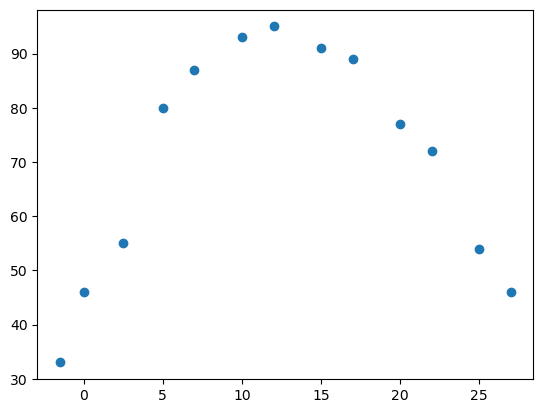

In [25]:
inputvalues = {
    'Temperature': [-1.5,0,2.5,5,7,10,12,15,17,20,22,25,27],
    'Efficiency': [33,46,55,80,87,93,95,91,89,77,72,54,46]
}
df = pd.DataFrame(inputvalues)
plt.scatter(df['Temperature'], df['Efficiency']);

### Polynomial regression

In [26]:
#Fit the regression model
temperature_sq = df['Temperature']**2
df2 = pd.DataFrame(temperature_sq)
df2 = df2.rename(columns = {'Temperature': 'Temperature_sq'})
df = pd.concat([df,df2], axis = 1)
print(df.head(5))

   Temperature  Efficiency  Temperature_sq
0         -1.5          33            2.25
1          0.0          46            0.00
2          2.5          55            6.25
3          5.0          80           25.00
4          7.0          87           49.00


In [27]:
#Model schatten
model = ols('Efficiency ~ Temperature + Temperature_sq', data=df).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             Efficiency   R-squared:                       0.974
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                     185.7
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.24e-08
Time:                        15:00:49   Log-Likelihood:                -33.963
No. Observations:                  13   AIC:                             73.93
Df Residuals:                      10   BIC:                             75.62
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         45.3253      2.071     21.

c:\Users\feeva\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:430: UserWarning: `kurtosistest` p-value may be inaccurate with fewer than 20 observations; only n=13 observations were given.
  return hypotest_fun_in(*args, **kwds)
